# Import Libraries

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load Dataset

In [26]:
# NOTE: SteamGames_1000 only used for test run, SteamGames is the full dataset and used on real run
df = pd.read_csv("data/origin/SteamGames.csv")
df.head(5)

,Appid,Name,Type,ReleaseDate,Genres,Developers,Publishers,Description,price,Thumbnail,Tags,ReviewScore,PositiveReview,NegativeReview,OsRequirement,MemoryRequirement,CpuRequirement,Rank
0,3764200,Resident Evil Requiem,game,"Feb 26, 2026","Action,Adventure","CAPCOM Co., Ltd.","CAPCOM Co., Ltd.",Resident Evil Requiem Deluxe Edition Resident ...,69.99$,https://shared.akamai.steamstatic.com/store_it...,NaN,9,23715,793,NaN,NaN,NaN,1
1,730,Counter-Strike 2,game,"Aug 21, 2012","Action,Free To Play",Valve,Valve,"For over two decades, Counter-Strike has offer...",0$,https://shared.akamai.steamstatic.com/store_it...,"FPS,Shooter,Multiplayer,Competitive,Action,Tea...",8,1214897,202393,Windows® 10,8 GB RAM,4 hardware CPU threads - Intel® Core™ i5 750 o...,2
2,1808500,ARC Raiders,game,"Oct 30, 2025",Action,Embark Studios,Embark Studios,ARC Raiders Deluxe Edition ARC Raiders Deluxe ...,39.99$,https://shared.akamai.steamstatic.com/store_it...,"Extraction Shooter,Multiplayer,PvP,PvE,Third-P...",8,149531,23194,Windows 10 or later 64-bit (latest update),12 GB RAM,Intel Core i5-6600K or AMD Ryzen R5 1600 proce...,3
3,359550,Tom Clancy's Rainbow Six Siege,game,"Dec 1, 2015","Action,Free To Play",Ubisoft Montreal,Ubisoft,Season 11 Year 1 Overview Year 11 Roadmap Free...,0$,https://shared.akamai.steamstatic.com/store_it...,NaN,8,522886,106839,NaN,NaN,NaN,4
4,1172470,Apex Legends™,game,"Nov 4, 2020","Action,Adventure,Free To Play",Respawn,Electronic Arts,Apex Legends: Breach About the Game Conquer wi...,0$,https://shared.akamai.steamstatic.com/store_it...,"Free to Play,Multiplayer,Battle Royale,FPS,Sho...",6,820,216,64-bit Windows 10,6 GB RAM,"AMD FX 4350 or Equivalent, Intel Core i3 6300 ...",5


In [27]:
# Transform price from str -> float
df['price'] = df['price'].transform(lambda x : x[:-1]).astype(float)
df['price']

0        69.99
1         0.00
2        39.99
3         0.00
4         0.00
         ...  
29926     1.99
29927     4.99
29928     4.99
29929     0.00
29930     2.99
Name: price, Length: 29931, dtype: float64

# Overview
## Missing value check

Number of rows have at least one missing value. There are **5536 rows with missing values**

In [28]:
df.isna().any(axis=1).sum()

np.int64(5536)

In [29]:
# Get features name 
features = df.columns.to_list()
features

['Appid',
 'Name',
 'Type',
 'ReleaseDate',
 'Genres',
 'Developers',
 'Publishers',
 'Description',
 'price',
 'Thumbnail',
 'Tags',
 'ReviewScore',
 'PositiveReview',
 'NegativeReview',
 'OsRequirement',
 'MemoryRequirement',
 'CpuRequirement',
 'Rank']

In [15]:
n = df.shape[0]

print("Count for missing value:")
for feature in features:
    print(f"\t'{feature}': {df[feature].isnull().sum()}/{n}")

Count for missing value:
	'Appid': 0/29931
	'Name': 0/29931
	'Type': 0/29931
	'ReleaseDate': 14/29931
	'Genres': 413/29931
	'Developers': 26/29931
	'Publishers': 1045/29931
	'Description': 52/29931
	'price': 0/29931
	'Thumbnail': 0/29931
	'Tags': 1614/29931
	'ReviewScore': 0/29931
	'PositiveReview': 0/29931
	'NegativeReview': 0/29931
	'OsRequirement': 2937/29931
	'MemoryRequirement': 3984/29931
	'CpuRequirement': 3859/29931
	'Rank': 0/29931


# Count For Unique Value

In [16]:
print("Number of unique value per feature")
for feature in features:
    print(f'{feature}: {len(df[feature].unique())}')

Number of unique value per feature
Appid: 29789
Name: 29779
Type: 6
ReleaseDate: 4417
Genres: 1186
Developers: 14778
Publishers: 11239
Description: 29652
price: 452
Thumbnail: 29786
Tags: 24683
ReviewScore: 10
PositiveReview: 3980
NegativeReview: 1793
OsRequirement: 4028
MemoryRequirement: 400
CpuRequirement: 8431
Rank: 16719


## Plots for Visualization

In [17]:
game_type_set = df['Type'].unique()
counts = df['Type'].value_counts()

counts

Type
game        22713
dlc          6586
music         600
mod            26
hardware        5
video           1
Name: count, dtype: int64

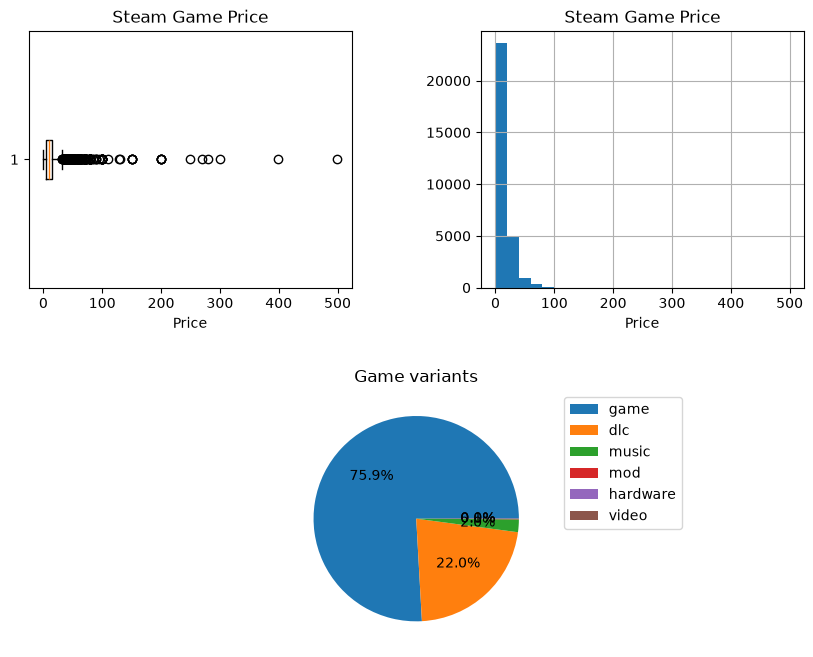

In [18]:
fig = plt.figure(figsize=(10, 8))
gs = fig.add_gridspec(2, 2, wspace=0.4, hspace=0.4)

# Top Left: Box plot, Feature: price
ax1 = fig.add_subplot(gs[0, 0])
ax1.boxplot(df["price"], orientation="horizontal")
ax1.set_title("Steam Game Price")
ax1.set_xlabel("Price")

# Top Right: Histogram, Feature: price
ax2 = fig.add_subplot(gs[0, 1])
ax2.hist(df["price"], bins=25, orientation="vertical")
ax2.set_title("Steam Game Price")
ax2.set_xlabel("Price")
ax2.grid(True)

# Bottom Row: Spans all columns (0 and 1), Feature: Type
ax3 = fig.add_subplot(gs[1, :])
ax3.pie(counts.values,
        autopct="%1.1f%%")
ax3.set_title("Game variants")
ax3.legend(labels=counts.index, 
           bbox_to_anchor=(1.05, 1),    # just outside the right upper edge
           loc="upper left")

## Extract Tag

In [19]:
tags_list = df['Tags'][df['Tags'].notna()]
tag_set = set()

for tags in tags_list:
    tag_list = tags.split(',')
    tag_set.update(tag_list)

print(f'Number of tag recorded: {len(tag_set)}')
print(f'Tag set: {tag_set}')
# Bring the tag set to a file for further purpose
with open('data/SteamGames_tags.txt', 'w') as r:
    for item in tag_set:
        r.write(f'{item}\n') 

Number of tag recorded: 446
Tag set: {'Team-Based', 'Hardware', 'Transportation', 'Audio Production', 'Sci-fi', 'Turn-Based Tactics', 'Bullet Hell', 'Classic', 'Conversation', 'Dark Humor', 'Medieval', 'Action RPG', 'Electronic', 'Touch-Friendly', 'Ambient', 'Co-op', 'Gaming', 'Life Sim', 'Mars', 'Mythology', 'Local Co-Op', 'Sailing', 'Dating Sim', 'Dark', 'Superhero', 'Dark Fantasy', 'Point & Click', 'Idler', 'Politics', 'Precision Platformer', 'Music-Based Procedural Generation', 'Beautiful', 'Multiplayer', 'Third-Person Shooter', 'Detective', 'Turn-Based', 'Otome', 'Fast-Paced', 'Choose Your Own Adventure', 'Psychedelic', 'Gambling', 'FPS', 'Comedy', 'Spelling', 'Capitalism', 'Experimental', 'Time Attack', 'Aliens', 'Elf', 'Transhumanism', 'Real Time Tactics', 'Gothic', 'Management', 'Party-Based RPG', 'World War I', 'Linear', 'Platformer', 'Tactical RPG', 'Colony Sim', 'Horror', 'Automation', 'Addictive', 'Nudity', 'Lore-Rich', 'Flight', 'Character Action Game', 'Lovecraftian', 'AT

--- 1. DATASET ARCHITECTURE & COMPOSITION ---
Total records: 29931

Breakdown by Application Type:
Type
game        22713
dlc          6586
music         600
mod            26
hardware        5
video           1
Name: count, dtype: int64

--- 2. CARDINALITY & DEDUPLICATION RISKS ---
Unique Appids: 29789 (Potential Duplicates: 142)
Unique Names: 29779 (Potential Duplicates: 152)
Unique Developers: 14777
Unique Publishers: 11238
Standardized Unique Tags: 446

--- 3. DATA QUALITY & MISSING VALUES ---
                   Missing Values  Percentage (%)
MemoryRequirement            3984           13.31
CpuRequirement               3859           12.89
OsRequirement                2937            9.81
Tags                         1614            5.39
Publishers                   1045            3.49
Genres                        413            1.38
Description                    52            0.17
Developers                     26            0.09
ReleaseDate                    14            0.

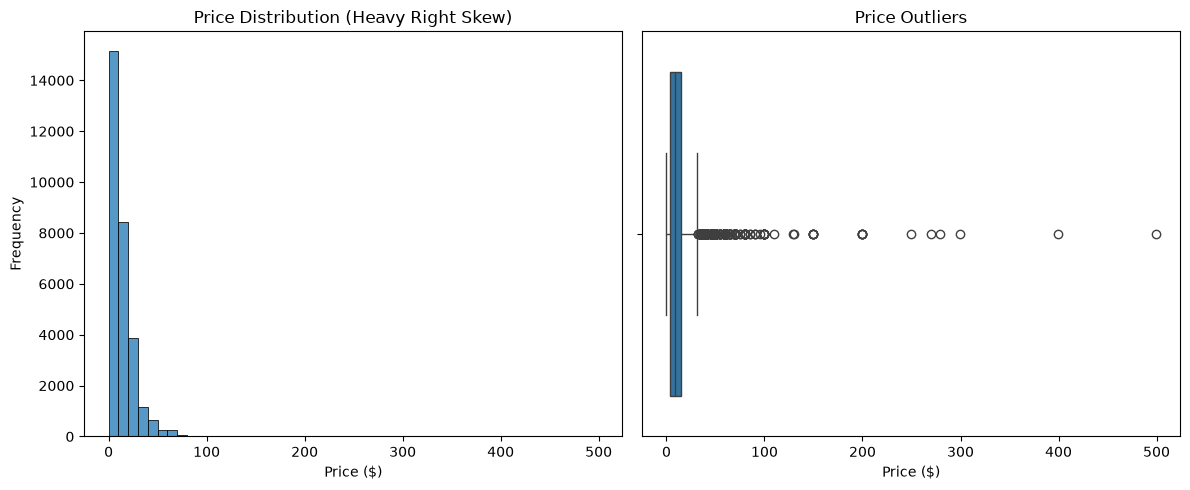

In [ ]:
print("--- 1. DATASET ARCHITECTURE & COMPOSITION ---")
print(f"Total records: {len(df)}")
print("\nBreakdown by Application Type:")
print(df['Type'].value_counts())

print("\n--- 2. CARDINALITY & DEDUPLICATION RISKS ---")
unique_appids = df['Appid'].nunique()
unique_names = df['Name'].nunique()
print(f"Unique Appids: {unique_appids} (Potential Duplicates: {len(df) - unique_appids})")
print(f"Unique Names: {unique_names} (Potential Duplicates: {len(df) - unique_names})")
print(f"Unique Developers: {df['Developers'].nunique()}")
print(f"Unique Publishers: {df['Publishers'].nunique()}")

# Calculate unique individual tags
tags_list = df['Tags'].dropna()
tag_set = set()
for tags in tags_list:
    tag_set.update(tags.split(','))
print(f"Standardized Unique Tags: {len(tag_set)}")

print("\n--- 3. DATA QUALITY & MISSING VALUES ---")
missing_counts = df.isnull().sum()
total_rows = len(df)
missing_df = pd.DataFrame({
    'Missing Values': missing_counts, 
    'Percentage (%)': (missing_counts / total_rows) * 100
})
# Filter and sort to show only columns with missing data
print(missing_df[missing_df['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False).round(2))

print("\n--- 4. FEATURE ENGINEERING: PRICE SKEWNESS ---")
# Strip the '$' sign and convert to float
df['price_clean'] = df['price'].astype(str).str.replace('$', '', regex=False).astype(float)

# Calculate statistical skewness (> 1 indicates highly right-skewed)
price_skew = df['price_clean'].skew()
print(f"Price Feature Skewness: {price_skew:.2f}")

# Visualize the right-skewed distribution
plt.figure(figsize=(12, 5))

# Plot 1: Histogram
plt.subplot(1, 2, 1)
sns.histplot(df['price_clean'], bins=50, kde=False)
plt.title("Price Distribution (Heavy Right Skew)")
plt.xlabel("Price ($)")
plt.ylabel("Frequency")

# Plot 2: Boxplot to highlight outliers
plt.subplot(1, 2, 2)
sns.boxplot(x=df['price_clean'])
plt.title("Price Outliers")
plt.xlabel("Price ($)")

plt.tight_layout()
plt.show()

## Missing Value Matrix

<Figure size 1000x600 with 0 Axes>

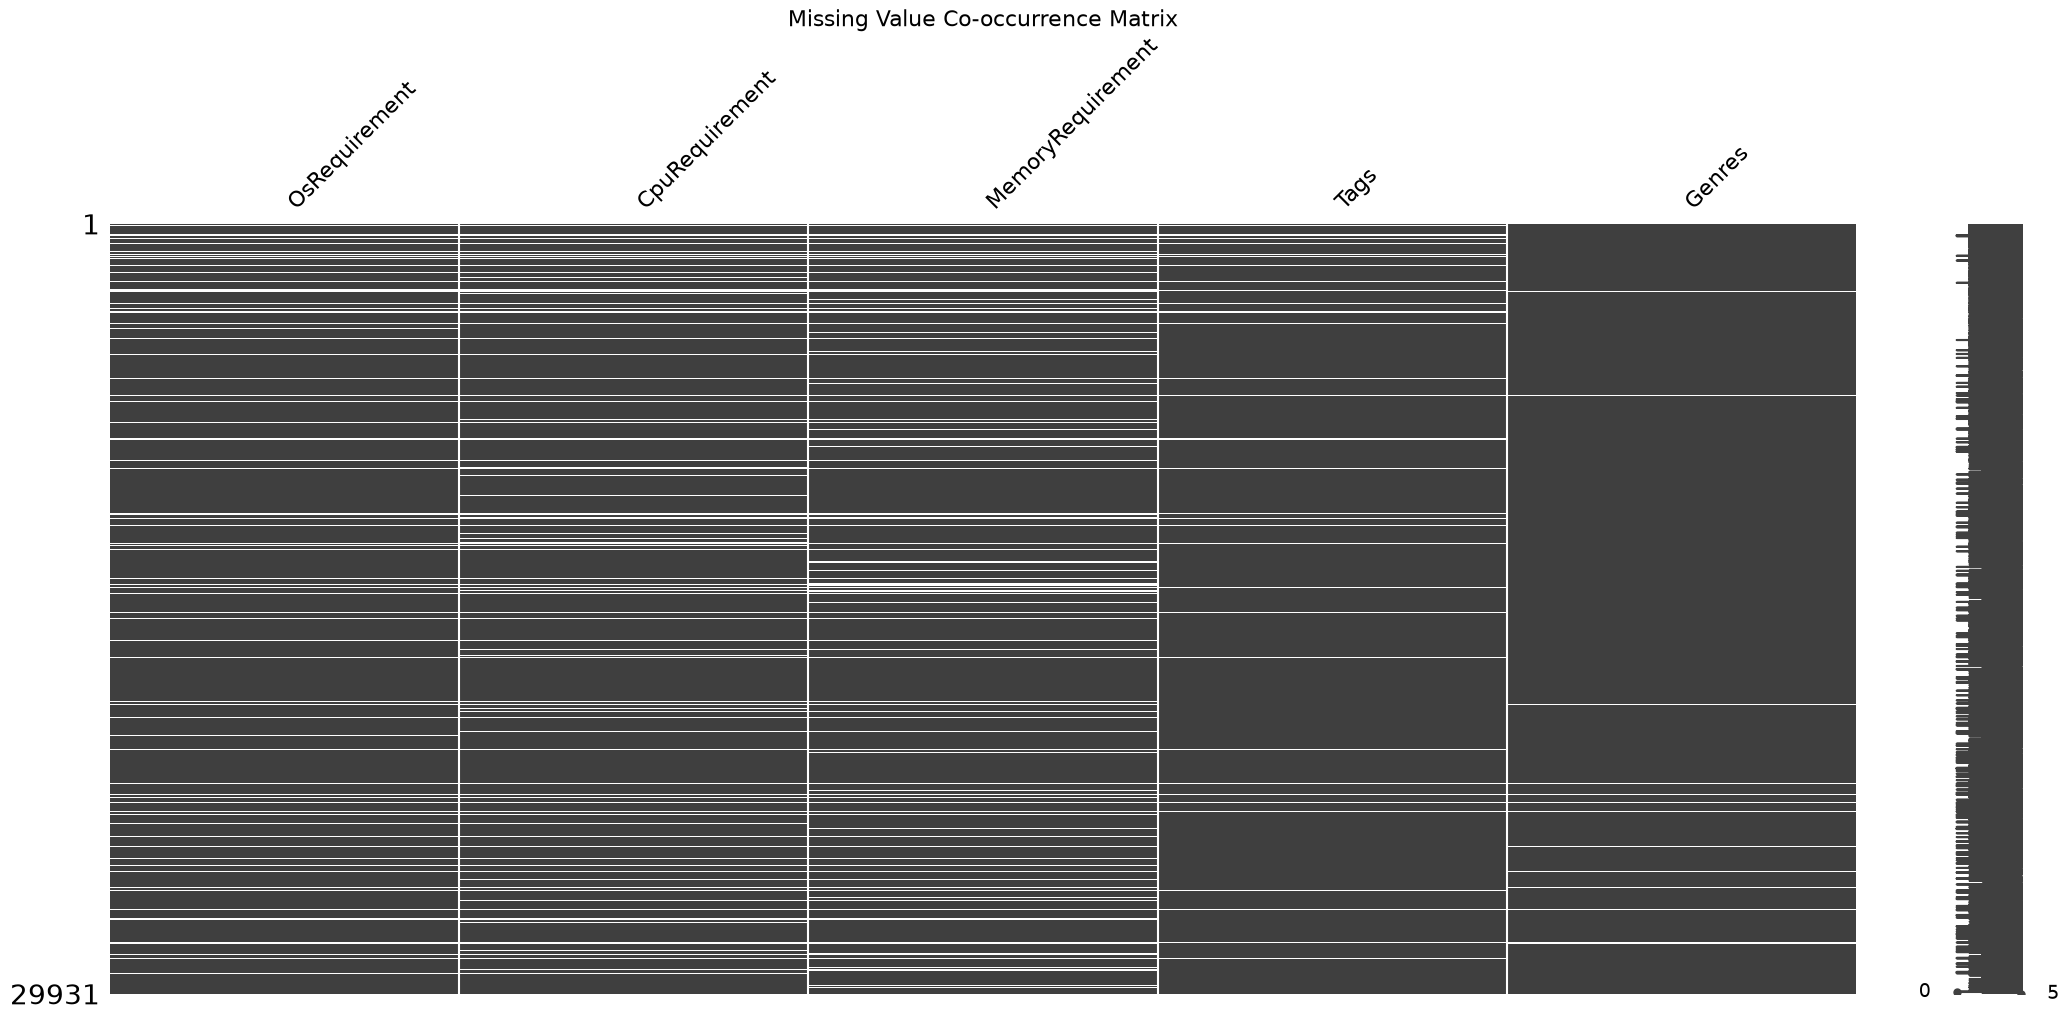

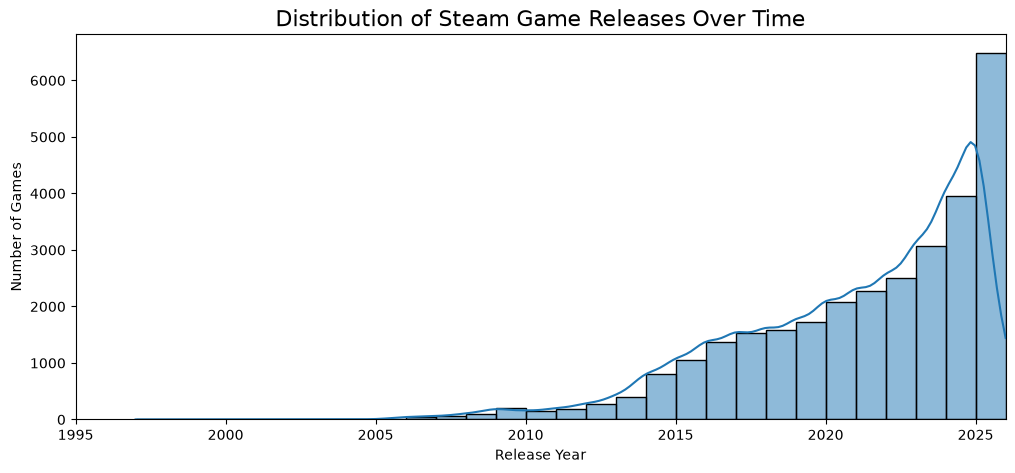

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msno

# 1. Missing Value Matrix
# Visualizes the overlap of missingness across your target imputation features
plt.figure(figsize=(10, 6))
msno.matrix(df[['OsRequirement', 'CpuRequirement', 'MemoryRequirement', 'Tags', 'Genres']])
plt.title("Missing Value Co-occurrence Matrix", fontsize=16)
plt.show()

# 2. Game Releases Over Time
# Extract the 4-digit year from the ReleaseDate string
df['ReleaseYear'] = df['ReleaseDate'].astype(str).str.extract(r'(20\d{2}|19\d{2})').astype(float)

plt.figure(figsize=(12, 5))
sns.histplot(df['ReleaseYear'].dropna(), bins=int(df['ReleaseYear'].max() - df['ReleaseYear'].min()), kde=True)
plt.title("Distribution of Steam Game Releases Over Time", fontsize=16)
plt.xlabel("Release Year")
plt.ylabel("Number of Games")
plt.xlim(1995, 2026) # Focus on modern eras
plt.show()